<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 4 · Regression</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/least-squares.html">Least squares</a> and <a href="/blogs/confidence-intervals.html">Confidence intervals</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

The usual standard error of a fitted trend assumes each residual is independent of the last. In temperature records it rarely is: a warm month tends to follow a warm month, so 360 monthly values carry the information of far fewer independent ones. On a synthetic 30-year monthly series with a true trend of 0.20 °C per decade, the naive 95% interval is ±0.040 °C per decade; allowing for the residuals' autocorrelation widens it to ±0.091. In trend-free series with the same persistence, the naive test finds a "significant" trend 31% of the time instead of 5%; an effective-sample-size correction brings that to 6%, Newey–West standard errors to 10%. The rank-based Mann–Kendall test resists outliers but not autocorrelation. Choosing the best of 16 start years makes false trends almost four times as common, and detecting 0.20 °C per decade in this noise takes about 19 years.

Check the residuals' autocorrelation before quoting any trend's p-value.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.signal import lfilter

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
c1, c2, c3, c4 = fallcolor.palette.discrete("default")
rng = np.random.default_rng(2026)

This module puts an interval on the slope from [Least squares](../least-squares.qmd), with the recipe of [Confidence intervals](../confidence-intervals.qmd), then asks what breaks when the data are a time series.

## The slope and its standard error

The slope's standard error says how much the fitted trend would change if the noise were drawn again. For a straight line fitted to $n$ points $(t_i, y_i)$,

$$
\mathrm{SE}(\hat b) = \frac{s}{\sqrt{S_{tt}}}, \qquad s^2 = \frac{1}{n-2}\sum_{i=1}^{n} r_i^2, \qquad S_{tt} = \sum_{i=1}^{n} (t_i - \bar t)^2,
$$

where $\hat b$ is the fitted slope (°C per year), $r_i$ the residuals (°C), $s$ their standard deviation (°C, with $n - 2$ because two parameters were fitted), and $t_i$ the time (years) with mean $\bar t$. The 95% interval is $\hat b \pm t^{*}\,\mathrm{SE}(\hat b)$, with $t^{*}$ the t multiplier on $n - 2$ degrees of freedom.

The example is synthetic: 30 years (360 months, labelled 1991–2020) of monthly temperature [anomalies](../anomalies/anomalies.ipynb) at an imaginary station:

$$
y_t = 0.02\,t + \varepsilon_t, \qquad \varepsilon_t = \phi\,\varepsilon_{t-1} + \eta_t,
$$

where $y_t$ is the anomaly (°C), $\varepsilon_t$ the noise (°C), $\phi = 0.6$ the share of each month's noise carried into the next (a first-order autoregressive, or AR(1), process), and $\eta_t$ independent normal shocks scaled so that $\varepsilon_t$ has a standard deviation of 0.30 °C. Both values were chosen for illustration, not taken from a real station.

In [2]:
def ar1_noise(phi, sd, n, size=None):
    """AR(1) noise: lag-1 correlation phi, standard deviation sd. A 200-step burn-in is dropped."""
    shape = (n + 200,) if size is None else (size, n + 200)
    shocks = rng.normal(0, sd * np.sqrt(1 - phi**2), shape)
    return lfilter([1], [1, -phi], shocks, axis=-1)[..., 200:]


t = np.arange(360) / 12                       # years since the start, one value per month
y = 0.02 * t + ar1_noise(0.6, 0.3, len(t))    # °C: 0.20 °C per decade plus AR(1) noise
fit = sm.OLS(y, sm.add_constant(t)).fit()
lo, hi = 10 * fit.conf_int()[1]
print(f"slope {10 * fit.params[1]:.3f} °C/decade, SE {10 * fit.bse[1]:.3f}, "
      f"95% CI {lo:.3f} to {hi:.3f}, p = {fit.pvalues[1]:.1e}")

slope 0.179 °C/decade, SE 0.020, 95% CI 0.139 to 0.218, p = 3.3e-17


Ordinary least squares recovers 0.179 °C per decade, with a 95% interval of 0.139 to 0.218 and $p = 3 \times 10^{-17}$. That interval treats the 360 residuals as independent; the right-hand panel below shows they are not. Autocorrelation leaves the slope unbiased but, as [Least squares](../least-squares.qmd) warns, makes its standard error too small.

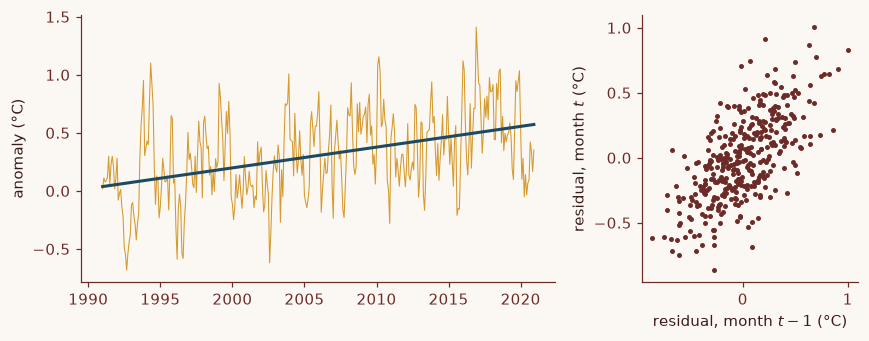

lag-1 correlation of the residuals r1 = 0.67


In [3]:
res = fit.resid
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
a.plot(1991 + t, y, color=c2, lw=0.7)
a.plot(1991 + t, fit.fittedvalues, color=c1, lw=2)
a.set_ylabel("anomaly (°C)")
b.scatter(res[:-1], res[1:], s=5, color=c3)
b.set(xlabel="residual, month $t-1$ (°C)", ylabel="residual, month $t$ (°C)")
fig.tight_layout()
plt.show()
print(f"lag-1 correlation of the residuals r1 = {np.corrcoef(res[:-1], res[1:])[0, 1]:.2f}")

<strong>Figure 1 | A trend plus persistent noise.</strong> Left: the synthetic series (thin) and its least-squares line (thick). Right: each residual against the previous month's; the slant, a lag-1 correlation of 0.67, is what the naive standard error ignores.

## Fewer independent months than you have

The correction most used in climate work replaces $n$ by an **effective sample size** $n_e$, the number of independent values that would give the same uncertainty. Santer and colleagues compute it from the lag-1 autocorrelation of the regression residuals and put $n_e - 2$ in place of $n - 2$[^1]^,^[^2]:

$$
n_e = n\,\frac{1 - r_1}{1 + r_1}, \qquad \mathrm{SE}_{\text{adj}}(\hat b) = \sqrt{\frac{\sum_i r_i^2 / (n_e - 2)}{S_{tt}}},
$$

where $r_1$ is the correlation between each residual and the one before it (dimensionless), the estimate of $\phi$, and the t multiplier uses $n_e - 2$ degrees of freedom. It must come from the residuals: in the raw series the trend itself makes neighbouring values alike, which pushes the lag-1 correlation towards 1 however independent the noise. Here 360 months count as about 71; [Variance and standard error](../variance-and-standard-error.qmd) uses the same formula for a mean. In Santer and colleagues' example, 252 months of tropical lower-troposphere temperature with $r_1 = 0.884$ count as about 16, and the adjusted standard error is over four times the unadjusted one[^2].

::: {.callout-note collapse="true"}
## Why the factor is (1 + φ)/(1 − φ)

The slope is a weighted sum of the observations, $\hat b = \sum_i w_i y_i$ with $w_i = (t_i - \bar t)/S_{tt}$, so

$$
\mathrm{Var}(\hat b) = \sum_i \sum_j w_i w_j\,\mathrm{Cov}(\varepsilon_i, \varepsilon_j).
$$

For independent noise only the $i = j$ terms survive, giving $\sigma^2/S_{tt}$, where $\sigma$ is the noise standard deviation. For AR(1) noise $\mathrm{Cov}(\varepsilon_i, \varepsilon_j) = \sigma^2 \phi^{|i-j|}$. When $n$ is large, neighbouring weights are almost equal, so each row of the double sum is close to $w_i^2 \sigma^2$ times

$$
1 + 2\sum_{k=1}^{\infty} \phi^k = 1 + \frac{2\phi}{1-\phi} = \frac{1+\phi}{1-\phi}.
$$

The variance is inflated by that factor, the same as dividing $n$ by it. This is my derivation of the standard large-sample result. It ignores the end points, whose large weights have neighbours on one side only; the cell below computes the double sum exactly.
:::

In [4]:
for n, phi in [(360, 0.6), (30, 0.6), (30, 0.3)]:
    x = np.arange(n)
    w = (x - x.mean()) / ((x - x.mean()) ** 2).sum()      # slope = sum of w_i * y_i
    corr = phi ** np.abs(x[:, None] - x[None, :])
    print(f"n = {n}, phi = {phi}: exact Var ratio {w @ corr @ w / (w @ w):.2f}, "
          f"large-n formula {(1 + phi) / (1 - phi):.2f}")

n = 360, phi = 0.6: exact Var ratio 3.94, large-n formula 4.00
n = 30, phi = 0.6: exact Var ratio 3.26, large-n formula 4.00
n = 30, phi = 0.3: exact Var ratio 1.74, large-n formula 1.86


For 360 months the approximation is close (3.94 against 4.00). The gap at 30 values (3.26 against 4.00) is the end-point effect the large-$n$ approximation ignores.

The second remedy changes the variance formula instead. A heteroskedasticity- and autocorrelation-consistent (HAC) standard error, in the form of Newey and West, estimates the double sum directly from products of residuals up to a chosen lag $L$, weighted so the variance cannot come out negative[^3]. It assumes no AR(1) shape, but $L$ must span the correlation. Copy this function for all three standard errors:

In [5]:
def trend_se(t, y, maxlags):
    """Least-squares slope of y on t with three standard errors and their p-values."""
    X = sm.add_constant(t)
    ols = sm.OLS(y, X).fit()
    n, r1 = len(y), np.corrcoef(ols.resid[:-1], ols.resid[1:])[0, 1]
    n_e = np.clip(n * (1 - r1) / (1 + r1), 3, n)   # my choice: never more than n, never below 3
    hac = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags}, use_t=True)
    out = pd.DataFrame(
        {"SE": [ols.bse[1], ols.bse[1] * np.sqrt((n - 2) / (n_e - 2)), hac.bse[1]],
         "df": [n - 2, n_e - 2, n - 2]},
        index=["naive OLS", "AR(1) effective n", f"Newey-West, {maxlags} lags"],
    )
    out["p"] = 2 * stats.t.sf(abs(ols.params[1]) / out.SE, out.df)
    out["95% half-width"] = stats.t.ppf(0.975, out.df) * out.SE
    return ols.params[1], out, n_e


slope, tab, n_e = trend_se(t, y, maxlags=12)
print(f"slope {10 * slope:.3f} °C/decade; effective sample size {n_e:.0f} of {len(y)} months")
pd.DataFrame({"SE (°C/decade)": (10 * tab.SE).round(3),
              "p": tab.p.map("{:.1e}".format),
              "95% CI (°C/decade)": [f"{10 * (slope - h):.3f} to {10 * (slope + h):.3f}" for h in tab["95% half-width"]]})

slope 0.179 °C/decade; effective sample size 71 of 360 months


,SE (°C/decade),p,95% CI (°C/decade)
naive OLS,0.020,3.3e-17,0.139 to 0.218
AR(1) effective n,0.046,2.1e-04,0.087 to 0.270
"Newey-West, 12 lags",0.044,5.1e-05,0.093 to 0.264


Both corrections roughly double the naive half-width, from ±0.040 to ±0.091 (AR(1)) or ±0.086 (Newey–West, 12 lags) °C per decade; the trend survives either way. The next cell draws 2000 series with **no trend at all** per setting (Mann–Kendall is explained in the next section) and counts how often each test calls the slope significant at the 5% level; an honest test does so about 5% of the time.

In [6]:
def false_positive_rates(phi, per_year, n_years=30, reps=2000):
    """Share of trend-free AR(1) series that each test calls significant at the 5% level."""
    t = np.arange(n_years * per_year) / per_year
    hits = []
    for y0 in ar1_noise(phi, 0.3, len(t), reps):
        _, tab0, _ = trend_se(t, y0, maxlags=12 if per_year == 12 else 3)
        hits.append([*(tab0.p < 0.05), stats.kendalltau(t, y0).pvalue < 0.05])
    return 100 * np.mean(hits, axis=0)


cases = [(phi, 12) for phi in (0, 0.3, 0.6, 0.9)] + [(phi, 1) for phi in (0, 0.3, 0.6)]
fpr = pd.DataFrame(
    [false_positive_rates(*c) for c in cases],
    index=[f"{'monthly' if k == 12 else 'annual'}, phi = {phi}" for phi, k in cases],
    columns=["naive", "AR(1) n_e", "Newey-West", "Mann-Kendall"],
)
fpr.round(1)   # % of 2000 trend-free series called significant; 5% is the target

,naive,AR(1) n_e,Newey-West,Mann-Kendall
"monthly, phi = 0",5.2,4.8,7.0,4.7
"monthly, phi = 0.3",15.0,5.4,8.3,15.1
"monthly, phi = 0.6",31.4,6.2,9.8,30.6
"monthly, phi = 0.9",66.7,6.7,24.0,66.1
"annual, phi = 0",5.7,4.9,12.1,5.5
"annual, phi = 0.3",14.3,8.1,17.3,13.4
"annual, phi = 0.6",31.2,9.2,25.1,28.4


At $\phi = 0.6$ the naive test finds a trend in 31.4% of trend-free monthly series, six times too often. The AR(1) correction holds at 6.2%, and 6.7% even at $\phi = 0.9$. Newey–West reaches 9.8%, then 24.0% at $\phi = 0.9$, once the correlation outlasts its 12 lags. The comparison favours the AR(1) correction because the synthetic noise is AR(1); with other memory, such as AR(2) or long-range dependence, the ranking may change, and that is not tested here.

The annual rows show a short record. With 30 points Newey–West has only 3 lags and few residual products per lag, too little to estimate the correlation, and reaches 25.1% at $\phi = 0.6$; the AR(1) correction reaches 9.2%. Zwiers and von Storch found the same for tests of a mean: once $n_e$ must be estimated the test becomes liberal, and the error is small only when the true $n_e$ exceeds about 30[^4]. Santer and colleagues note that their trend test inherits this[^2].

The 0.23 ± 0.05 °C per decade in [Anomalies](../anomalies/anomalies.ipynb), from least squares on 43 annual means, likewise assumes independent residuals.

## Mann–Kendall and Sen's slope

Hydrology and air-quality work often use two rank-based tools that assume nothing about the noise's distribution. The **Mann–Kendall** test asks, for every pair of times, whether the later value is higher:

$$
S = \sum_{i<j} \operatorname{sign}(y_j - y_i),
$$

where $\operatorname{sign}$ is $+1$, $-1$ or $0$. Divided by the number of pairs, $n(n-1)/2$, $S$ is Kendall's rank correlation $\tau$ between time and value (with no ties), so `scipy.stats.kendalltau` runs the test. **Sen's slope** is the median of the slopes $(y_j - y_i)/(t_j - t_i)$ over all pairs, an estimator built to resist gross errors[^5]; `scipy.stats.theilslopes` returns it with an interval.

In [7]:
mk = stats.kendalltau(t, y)
sen = stats.theilslopes(y, t)
print(f"Mann-Kendall: tau = {mk.statistic:.3f}, p = {mk.pvalue:.1e}")
print(f"Sen's slope {10 * sen.slope:.3f} °C/decade, 95% CI {10 * sen.low_slope:.3f} to {10 * sen.high_slope:.3f}")

y_bad = y + np.r_[np.zeros(359), 3.0]   # one faulty reading in the final month
print(f"with one +3 °C error in the last month: least squares {10 * sm.OLS(y_bad, sm.add_constant(t)).fit().params[1]:.3f}, "
      f"Sen {10 * stats.theilslopes(y_bad, t).slope:.3f} °C/decade")

Mann-Kendall: tau = 0.285, p = 6.7e-16
Sen's slope 0.181 °C/decade, 95% CI 0.139 to 0.223
with one +3 °C error in the last month: least squares 0.195, Sen 0.186 °C/decade


Sen's slope, 0.181 °C per decade, agrees with least squares and is steadier when the data hold a mistake: one faulty +3 °C reading in the final month moves the least-squares slope from 0.179 to 0.195, Sen's to 0.186.

On autocorrelation the rank methods are no better than the naive test. Sen's interval, 0.139 to 0.223, is as narrow as the naive one, and Mann–Kendall tracks the naive column of the table: 30.6% false positives at $\phi = 0.6$. The reason is that its p-value compares $S$ with the variance $S$ would have for independent data, $n(n-1)(2n+5)/18$ without ties. Yue and colleagues show that serial correlation changes that variance and that pre-whitening to remove it also shrinks a real trend; they recommend removing the trend before estimating the autocorrelation[^6]. The `pymannkendall` package implements several corrected tests.

## Chosen start dates, and how long a record you need

A trend's p-value holds only for a window fixed before looking at the data. Rahmstorf and colleagues make this point about the warming "slowdown" claimed for 2001–2014: a period selected for its low trend from many possible intervals cannot be tested as if it were a random draw[^7]. The next cell tests trend-free monthly series ($\phi = 0.6$) over the full 30 years, then from each start year 0 to 15, keeping the smallest AR(1)-corrected p-value.

In [8]:
fixed, searched = [], []   # windows start in years 0-15 and all end in the final month
for y0 in ar1_noise(0.6, 0.3, 360, 1000):
    p = [trend_se(t[12 * s:], y0[12 * s:], 12)[1].p.iloc[1] for s in range(16)]
    fixed.append(p[0] < 0.05)
    searched.append(min(p) < 0.05)
print(f"AR(1)-corrected test, false positives: full record {100 * np.mean(fixed):.1f}%, "
      f"best of 16 start years {100 * np.mean(searched):.1f}%")

AR(1)-corrected test, false positives: full record 6.4%, best of 16 start years 23.5%


The full record gives 6.4% false positives; the best of 16 start years gives 23.5%, almost four times as many, although each test was honest.

How long must a record be? For $N$ years with $m$ evenly spaced values per year, $S_{tt} \approx m N^3 / 12$, so the corrected standard error is about $\sigma \sqrt{12/m}\, N^{-3/2} \sqrt{(1+\phi)/(1-\phi)}$. A trend is detected with 80% probability at the 5% level when it lies $z = 1.96 + 0.84 = 2.80$ standard errors from zero, which gives

$$
N \approx \left[ \frac{z\,\sigma}{|\omega|} \sqrt{\frac{12}{m}} \sqrt{\frac{1+\phi}{1-\phi}} \right]^{2/3},
$$

where $N$ is the record length (years), $\sigma$ the noise standard deviation (°C), $\omega$ the trend (°C per year), and $\phi$ the lag-1 autocorrelation at the data's own time step. This is my derivation, ignoring the error in estimating $\phi$ and $\sigma$. Weatherhead and colleagues give formulas of this kind for monitoring stations, and find that a level shift such as an instrument change can raise the years needed by 50% or more[^8].

In [9]:
def years_needed(trend, sd, phi, per_year=12, power=0.8, alpha=0.05):
    z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return (z * sd / abs(trend) * np.sqrt(12 / per_year) * np.sqrt((1 + phi) / (1 - phi))) ** (2 / 3)


for phi in (0, 0.3, 0.6, 0.9):
    print(f"phi = {phi}: {years_needed(0.02, 0.3, phi):.1f} years for 0.20 °C/decade, monthly SD 0.3 °C")

for n_years in (10, 15, 20, 25):
    tn = np.arange(12 * n_years) / 12
    hit = [trend_se(tn, 0.02 * tn + e, 12)[1].p.iloc[1] < 0.05 for e in ar1_noise(0.6, 0.3, len(tn), 1000)]
    print(f"simulated, phi = 0.6, {n_years} years: detected in {100 * np.mean(hit):.1f}% of series")

phi = 0: 12.1 years for 0.20 °C/decade, monthly SD 0.3 °C
phi = 0.3: 14.9 years for 0.20 °C/decade, monthly SD 0.3 °C
phi = 0.6: 19.2 years for 0.20 °C/decade, monthly SD 0.3 °C
phi = 0.9: 32.3 years for 0.20 °C/decade, monthly SD 0.3 °C


simulated, phi = 0.6, 10 years: detected in 17.9% of series


simulated, phi = 0.6, 15 years: detected in 48.4% of series


simulated, phi = 0.6, 20 years: detected in 82.7% of series


simulated, phi = 0.6, 25 years: detected in 98.6% of series


For 0.20 °C per decade in monthly noise of 0.30 °C, independent months need about 12 years, $\phi = 0.6$ needs 19, and $\phi = 0.9$ needs 32. The simulation agrees: at $\phi = 0.6$ the corrected test detects the trend in 48.4% of 15-year records and 82.7% of 20-year ones.

::: {.callout-tip}
## What this means for you

My inference from the simulations and sources above:

- Report estimate, interval and method: "0.18 °C per decade (95% CI 0.09 to 0.27; AR(1)-adjusted, $n_e = 71$ of 360 months)".
- Fix the window before looking; if you explore several, report them all.
- Before a monitoring programme starts, check that the trend you care about is detectable in the years you have.
:::

## Key takeaways

- Plot each residual against the previous one before reading any trend's p-value.
- For roughly AR(1) noise use the effective-sample-size correction; for long series of unknown correlation shape, Newey–West with a lag spanning the correlation.
- When $n_e$ is below about 30, treat a corrected p-value near 0.05 as inconclusive.
- Use Mann–Kendall and Sen's slope against outliers, not against autocorrelation.
- Count the windows, start years and series you tried; the best one's p-value is not a 5% test.

## References

[^1]: Santer, B. D. et al. Statistical significance of trends and trend differences in layer-average atmospheric temperature time series. *J. Geophys. Res. Atmos.* **105**, 7337–7356 (2000). https://doi.org/10.1029/1999JD901105
[^2]: Santer, B. D. et al. Consistency of modelled and observed temperature trends in the tropical troposphere. *Int. J. Climatol.* **28**, 1703–1722 (2008). https://doi.org/10.1002/joc.1756
[^3]: Newey, W. K. & West, K. D. A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica* **55**, 703–708 (1987). https://doi.org/10.2307/1913610
[^4]: Zwiers, F. W. & von Storch, H. Taking serial correlation into account in tests of the mean. *J. Clim.* **8**, 336–351 (1995). https://doi.org/10.1175/1520-0442(1995)008%3C0336:TSCIAI%3E2.0.CO;2
[^5]: Sen, P. K. Estimates of the regression coefficient based on Kendall's tau. *J. Am. Stat. Assoc.* **63**, 1379–1389 (1968). https://doi.org/10.1080/01621459.1968.10480934
[^6]: Yue, S., Pilon, P., Phinney, B. & Cavadias, G. The influence of autocorrelation on the ability to detect trend in hydrological series. *Hydrol. Process.* **16**, 1807–1829 (2002). https://doi.org/10.1002/hyp.1095
[^7]: Rahmstorf, S., Foster, G. & Cahill, N. Global temperature evolution: recent trends and some pitfalls. *Environ. Res. Lett.* **12**, 054001 (2017). https://doi.org/10.1088/1748-9326/aa6825
[^8]: Weatherhead, E. C. et al. Factors affecting the detection of trends: statistical considerations and applications to environmental data. *J. Geophys. Res. Atmos.* **103**, 17149–17161 (1998). https://doi.org/10.1029/98JD00995

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/least-squares.html"><span>Previous</span>Least squares</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/reading-residuals/reading_residuals.html"><span>Next</span>Reading residuals</a></div>
<!-- CURRICULUM_FOOTER_END -->